# Titanic — исследовательский анализ данных (EDA)

Нужно понять структуру данных, качество признаков и их связь с Survived,
чтобы составить гипотезы для будущих экспериментов. Одна строка — запись о пассажире.
Данные — локальные данные data/classification/train.csv и test.csv.

## 1. Окружение и загрузка

In [1]:
import sys
from pathlib import Path

import pandas as pd

print("Python: ", sys.executable)
print("Work dir: ", Path.cwd())
print("pandas: ", pd.__version__)

import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")

Python:  C:\Users\toni1\notebooks\ML mentor\ml_project\.venv\Scripts\python.exe
Work dir:  C:\Users\toni1\notebooks\ML mentor\ml_project\notebooks
pandas:  3.0.6


In [2]:
data_dir = Path("../data/classification")

train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")

print("train: ", train.shape)
print("test: ", test.shape)

# Исследование не должно менять сырые данные. В конце проверим
raw_train = train.copy(deep=True)
raw_test = test.copy(deep=True)

train:  (891, 12)
test:  (418, 11)


In [3]:
display(train.head(3))
display(test.head(3))
display(pd.DataFrame({"train_dtype": train.dtypes.astype(str),
                      "test_dtype": test.dtypes.astype(str)}))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q


,train_dtype,test_dtype
Age,float64,float64
Cabin,str,str
Embarked,str,str
Fare,float64,float64
Name,str,str
Parch,int64,int64
PassengerId,int64,int64
Pclass,int64,int64
Sex,str,str
SibSp,int64,int64


## 2. Первичный обзор

In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


В train 891 запись и 12 столбцов. Survived — таргет, PassengerId — ID.
Age, Cabin, Embarked содержат пропуски. Pclass хранится числом, но обозначает
упорядоченную категорию.
Тип str показывает текстовые поля; кодирование выберем позже.

In [5]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [6]:
train.nunique().sort_values()

Survived         2
Sex              2
Pclass           3
Embarked         3
Parch            7
SibSp            7
Age             88
Cabin          147
Fare           248
Ticket         681
PassengerId    891
Name           891
dtype: int64

In [7]:
print("Duplicates :", train.duplicated().sum())

Duplicates : 0


Выводы первичного обзора.

- Для известного возраста медиана — 28 лет, диапазон — 0.42–80.
- Для Fare среднее ≈32.20, медиана ≈14.45, максимум ≈512.33:
  среднее заметно выше медианы, возможен длинный правый хвост. Проверим графиками.
- Встречается нулевой Fare.
- Name обычно не несет инфы.
- Повторы Ticket могут обозначать совместные билеты/группы.
- Полных дубликатов нет. Уникальный ID может скрывать повторы остальных полей — отдельно проверим их ниже.


## 3. Распределение таргета

In [8]:
target_counts = train["Survived"].value_counts().sort_index()
target_percent = (
    train["Survived"].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    "count": target_counts,
    "percent": target_percent,
})

target_summary

,count,percent
Survived,,
0,549,61.616162
1,342,38.383838


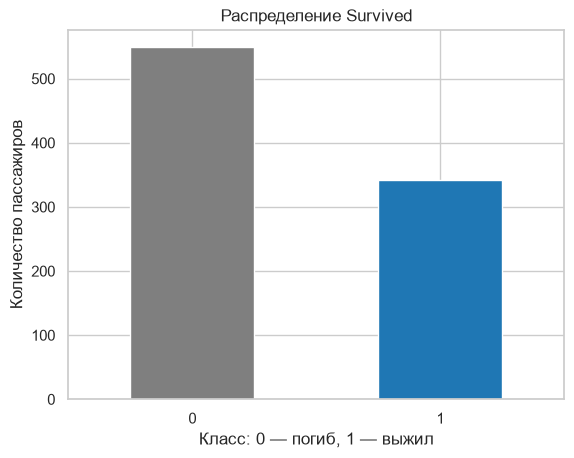

In [9]:
import matplotlib.pyplot as plt

target_counts.plot(
    kind="bar",
    color=["tab:gray", "tab:blue"],
)

plt.title("Распределение Survived")
plt.xlabel("Класс: 0 — погиб, 1 — выжил")
plt.ylabel("Количество пассажиров")
plt.xticks(rotation=0)
plt.show()

В train 549 погибших (61.62%) и 342 выживших (38.38%).
Классы несбалансированы, но оба представлены сотнями записей.

Стратификация поможет сохранить доли классов.

## 4. Пропуски

In [10]:
missing_summary = pd.DataFrame({
    "train_count": train.isna().sum(),
    "train_percent": train.isna().mean() * 100,
    "test_count": test.isna().sum(),
    "test_percent": test.isna().mean() * 100,
})

missing_summary = missing_summary.drop(index="Survived")

missing_summary = missing_summary[
    (missing_summary["train_count"] > 0)
    | (missing_summary["test_count"] > 0)
]

missing_summary.round(2)

,train_count,train_percent,test_count,test_percent
Age,177,19.87,86.0,20.57
Cabin,687,77.10,327.0,78.23
Embarked,2,0.22,0.0,0.00
Fare,0,0.00,1.0,0.24


Вывод: Пропуски Age: 19.87% в train и 20.57% в test;
Cabin - 77.10% и 78.23%.
Embarked отсутствует у двух записей train, Fare — у одной записи test.

Обработку нужно предусмотреть для всех четырёх полей. Медиана для Age, заполнение категории
Embarked, удаление сырого Cabin с индикатором его наличия - все это кандидаты для будущей CV.
Медианы и частые категории будем определять на train-части каждого фолда

## 5. Числовые признаки и необычные значения

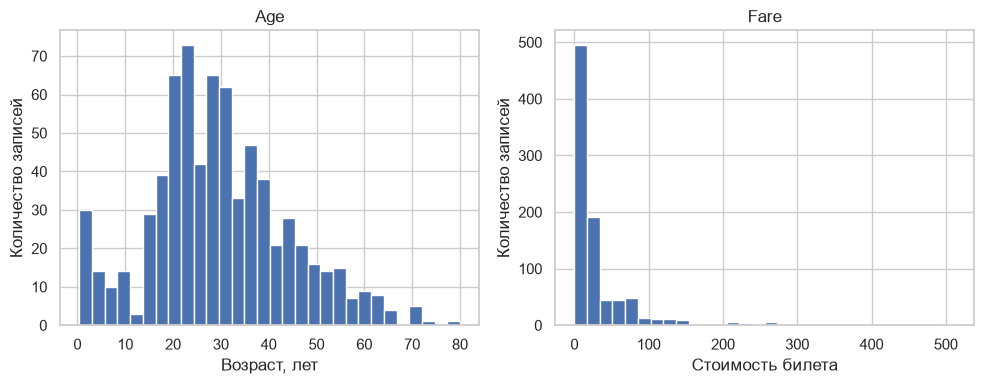

In [11]:
import matplotlib.pyplot as plt

hist_axes = train[["Age", "Fare"]].hist(bins=30, figsize=(10, 4))
hist_axes[0, 0].set_xlabel("Возраст, лет")
hist_axes[0, 1].set_xlabel("Стоимость билета")
for ax in hist_axes.flat:
    ax.set_ylabel("Количество записей")
plt.tight_layout()
plt.show()

Среди пассажиров с известным возрастом самая плотная часть распределения находится в диапазоне от 20 до 40 лет. Также есть и дети и старики.

Распределение платы за билет сильно ассиметрично: большинство пассажиров с дешевыми билетами, но есть и большие значения.

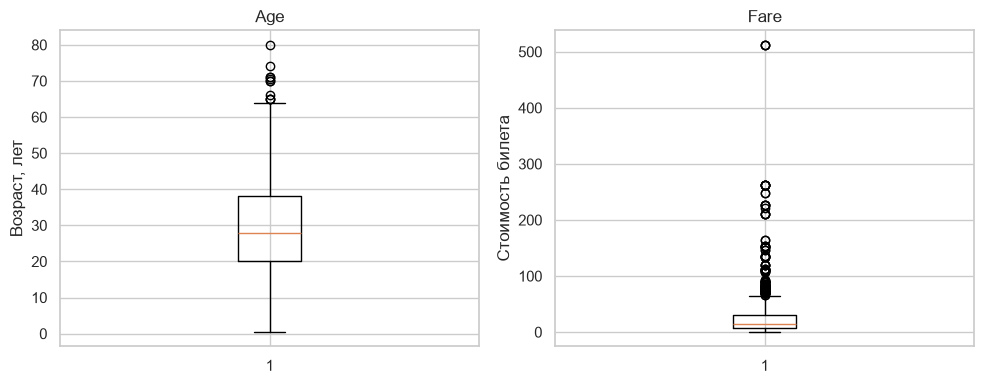

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].boxplot(train["Age"].dropna())
axes[0].set_title("Age")
axes[0].set_ylabel("Возраст, лет")

axes[1].boxplot(train["Fare"].dropna())
axes[1].set_title("Fare")
axes[1].set_ylabel("Стоимость билета")

plt.tight_layout()
plt.show()

In [13]:
train[["Age", "Fare"]].skew()

Age     0.389108
Fare    4.787317
dtype: float64

In [14]:
train.nlargest(10, "Fare")[
    ["PassengerId", "Pclass", "Fare"]
]

,PassengerId,Pclass,Fare
258,259,1,512.3292
679,680,1,512.3292
737,738,1,512.3292
27,28,1,263.0000
88,89,1,263.0000
341,342,1,263.0000
438,439,1,263.0000
311,312,1,262.3750
742,743,1,262.3750
118,119,1,247.5208


Асимметрия Age ≈0.39, Fare ≈4.79: у стоимости билета выраженный правый хвост.
В десяти строках с наибольшим Fare все пассажиры относятся к первому классу.

логарифмируем Fare — гипотеза для CV

In [15]:
train["SibSp"].value_counts().sort_index()

SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

In [16]:
train["Parch"].value_counts().sort_index()

Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64

У большинства записей SibSp=0, у большинства Parch=0.

## 6. Категории и новые значения test

In [17]:
for column in ["Sex", "Pclass", "Embarked"]:
    print(f"Признак: {column}")
    print(train[column].value_counts(dropna=False))
    print()

Признак: Sex
Sex
male      577
female    314
Name: count, dtype: int64

Признак: Pclass
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Признак: Embarked
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64



In [18]:
for column in ["Sex", "Pclass", "Embarked"]:
    train_categories = set(train[column].dropna().unique())
    test_categories = set(test[column].dropna().unique())

    print(f"Признак: {column}")
    print("Только в train:", sorted(train_categories - test_categories))
    print("Только в test:", sorted(test_categories - train_categories))
    print()

Признак: Sex
Только в train: []
Только в test: []

Признак: Pclass
Только в train: []
Только в test: []

Признак: Embarked
Только в train: []
Только в test: []



Для Sex, Pclass, Embarked наборы непропущенных категорий train/test совпадают.

In [19]:
for column in ["Name", "Ticket", "Cabin"]:
    counts = train[column].value_counts()

    print(f"Признак: {column}")
    print("Уникальных значений:", counts.size)
    print("Значений, встречающихся один раз:", (counts == 1).sum())
    print("Пять самых частых значений:")
    print(counts.head(5))
    print()

Признак: Name
Уникальных значений: 891
Значений, встречающихся один раз: 891
Пять самых частых значений:
Name
Braund, Mr. Owen Harris                                1
Cumings, Mrs. John Bradley (Florence Briggs Thayer)    1
Heikkinen, Miss. Laina                                 1
Futrelle, Mrs. Jacques Heath (Lily May Peel)           1
Allen, Mr. William Henry                               1
Name: count, dtype: int64

Признак: Ticket
Уникальных значений: 681
Значений, встречающихся один раз: 547
Пять самых частых значений:
Ticket
347082      7
1601        7
CA. 2343    7
3101295     6
CA 2144     6
Name: count, dtype: int64

Признак: Cabin
Уникальных значений: 147
Значений, встречающихся один раз: 101
Пять самых частых значений:
Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F33            3
E101           3
Name: count, dtype: int64



Все имена в train уникальны. Ticket и Cabin повторяются,
но содержат много значений с единственной записью.
Прямой one-hot для сырых строк создаст множество редких колонок, особенно для Name.

In [20]:
for column in ["Name", "Ticket", "Cabin"]:
    train_values = set(train[column].dropna().unique())
    test_values = test[column].dropna()

    new_values = set(test_values.unique()) - train_values
    new_value_rows = test_values.isin(new_values)

    print(f"Признак: {column}")
    print("Новых уникальных значений в test:", len(new_values))
    print("Строк test с новыми значениями:", new_value_rows.sum())
    print("Всего заполненных строк test:", len(test_values))
    print()

Признак: Name
Новых уникальных значений в test: 416
Строк test с новыми значениями: 416
Всего заполненных строк test: 418

Признак: Ticket
Новых уникальных значений в test: 248
Строк test с новыми значениями: 266
Всего заполненных строк test: 418

Признак: Cabin
Новых уникальных значений в test: 39
Строк test с новыми значениями: 46
Всего заполненных строк test: 91



## 7. Категории и выживаемость

In [21]:
sex_summary = train.groupby("Sex")["Survived"].agg(
    count="count",
    survived="sum",
    survival_percent="mean",
)

sex_summary["survival_percent"] *= 100

sex_summary.round(2)

,count,survived,survival_percent
Sex,,,
female,314,233,74.20
male,577,109,18.89


В train выжили 233 из 314 женщин (74.20%) и 109 из 577 мужчин (18.89%).
Sex сильно связан с исходом. Это описание, не доказательство причинного эффекта.
Далее сравним классы билета и сочетания Sex × Pclass.

In [22]:
pclass_summary = train.groupby("Pclass")["Survived"].agg(
    count="count",
    survived="sum",
    survival_percent="mean",
)

pclass_summary["survival_percent"] *= 100

pclass_summary.round(2)

,count,survived,survival_percent
Pclass,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24


В первом классе выжили 62.96%, во втором — 47.28%,
в третьем — 24.24%. 
Видно связь класса билета с исходом

### 7.1. Пол и класс вместе

count  survived  survival_percent
Sex    Pclass                                   
female 1          94        91             96.81
       2          76        70             92.11
       3         144        72             50.00
male   1         122        45             36.89
       2         108        17             15.74
       3         347        47             13.54

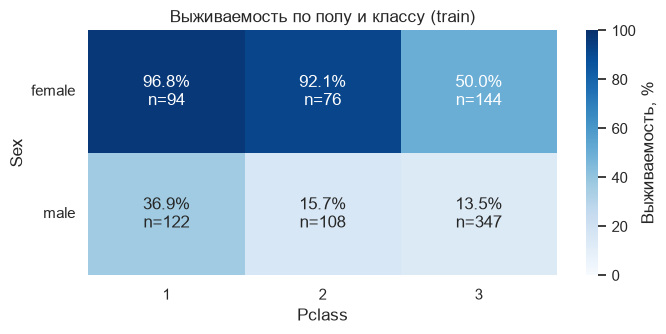

In [23]:
sex_pclass_summary = train.groupby(["Sex", "Pclass"])["Survived"].agg(
    count="count", survived="sum", survival_percent="mean",
)
sex_pclass_summary["survival_percent"] *= 100
display(sex_pclass_summary.round(2))

rates = sex_pclass_summary["survival_percent"].unstack("Pclass")
sizes = sex_pclass_summary["count"].unstack("Pclass")
labels = rates.copy().astype(object)
for sex in rates.index:
    for pclass in rates.columns:
        labels.loc[sex, pclass] = f"{rates.loc[sex, pclass]:.1f}%\nn={sizes.loc[sex, pclass]}"

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.heatmap(rates, annot=labels, fmt="", vmin=0, vmax=100, cmap="Blues",
            cbar_kws={"label": "Выживаемость, %"}, ax=ax)
ax.set(title="Выживаемость по полу и классу (train)", xlabel="Pclass", ylabel="Sex")
ax.tick_params(axis="y", labelrotation=0)
fig.tight_layout()
plt.show()

В каждом из трёх классов доля выживших среди женщин выше, чем среди мужчин.
У женщин третьего класса она ниже, чем у женщин первого/второго. Совместный анализ показывает
структуру, которую одна общая средняя скрывает. Sex * Pclass — гипотеза взаимодействия для CV.

### 7.2. Порт посадки

In [24]:
embarked_groups = train["Embarked"].fillna("Unknown")
embarked_summary = train.groupby(embarked_groups)["Survived"].agg(
    count="count", survived="sum", survival_percent="mean",
)
embarked_summary["survival_percent"] *= 100
display(embarked_summary.round(2))
display(pd.crosstab(embarked_groups, train["Pclass"], normalize="index").mul(100).round(2))

,count,survived,survival_percent
Embarked,,,
C,168,93,55.36
Q,77,30,38.96
S,644,217,33.70
Unknown,2,2,100.00


Pclass,1,2,3
Embarked,,,
C,50.60,10.12,39.29
Q,2.60,3.90,93.51
S,19.72,25.47,54.81
Unknown,100.00,0.00,0.00


Выживаемость и состав классов различаются между портами.
Для группы Unknown всего две записи

## 8. Возраст, стоимость и выживаемость

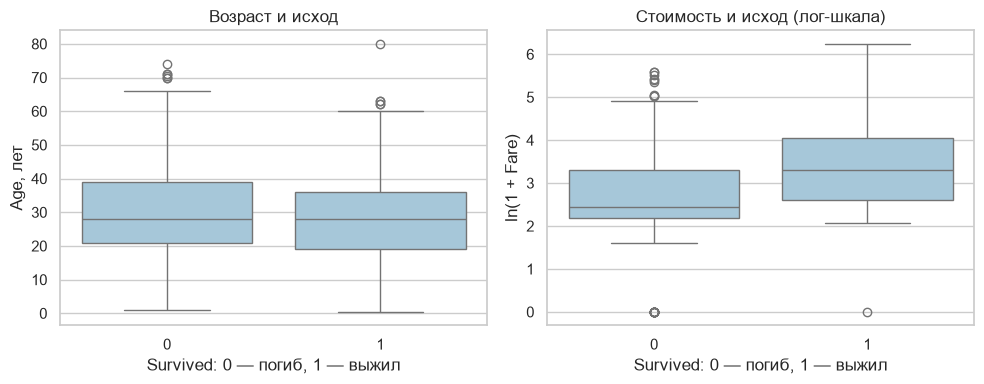

Age         Fare       
         count median count median
Survived                          
0          424   28.0   549   10.5
1          290   28.0   342   26.0

In [25]:
eda_train = train.copy()
eda_train["LogFare"] = np.log1p(eda_train["Fare"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=eda_train, x="Survived", y="Age", color="#9ecae1", ax=axes[0])
sns.boxplot(data=eda_train, x="Survived", y="LogFare", color="#9ecae1", ax=axes[1])
axes[0].set(title="Возраст и исход", ylabel="Age, лет")
axes[1].set(title="Стоимость и исход (лог-шкала)", ylabel="ln(1 + Fare)")
for ax in axes:
    ax.set_xlabel("Survived: 0 — погиб, 1 — выжил")
fig.tight_layout()
plt.show()
display(train.groupby("Survived")[["Age", "Fare"]].agg(["count", "median"]).round(2))

Медианы известного возраста близки; медиана стоимости у выживших выше.

### 8.1. Возрастные группы

,count,survived,survival_percent
AgeBand,,,
0–<12,68,39,57.35
12–<18,45,22,48.89
18–<30,271,95,35.06
30–<45,215,91,42.33
45–<60,89,36,40.45
60+,26,7,26.92
Unknown,177,52,29.38


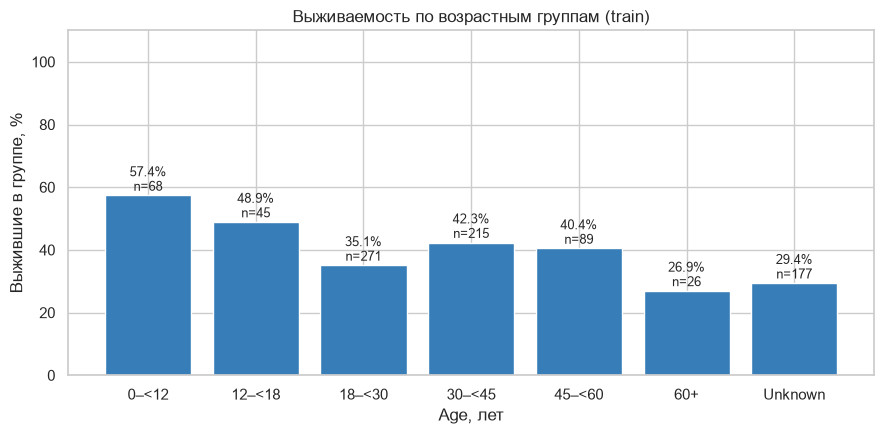

In [37]:
eda_train["AgeBand"] = pd.cut(
    eda_train["Age"], bins=[0, 12, 18, 30, 45, 60, np.inf], 
    right=False,
    labels=["0–<12", "12–<18", "18–<30", "30–<45", "45–<60", "60+"],
).cat.add_categories(["Unknown"]).fillna("Unknown")
age_summary = eda_train.groupby("AgeBand", observed=True)["Survived"].agg(
    count="count", 
    survived="sum", 
    survival_percent="mean",
)
age_summary["survival_percent"] *= 100
display(age_summary.round(2))

# хелпер для построения графика
def plot_survival(summary, title, xlabel):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    bars = ax.bar(summary.index.astype(str), summary["survival_percent"], color="#377eb8")
    for bar, rate, size in zip(bars, summary["survival_percent"], summary["count"]):
        ax.text(bar.get_x() + bar.get_width()/2, rate + 1.5,
                f"{rate:.1f}%\nn={size}", ha="center", fontsize=9)
    ax.set(title=title, xlabel=xlabel, ylabel="Выжившие в группе, %", ylim=(0, 110))
    ax.set_yticks([0, 20, 40, 60, 80, 100])
    fig.tight_layout()
    plt.show()

plot_survival(age_summary, "Выживаемость по возрастным группам (train)", "Age, лет")

Среди детей младше 12 лет доля выживших выше, чем в большинстве взрослых групп. Детей старались спасти в первую очередь.

## 9. Родственники и индикаторы пропусков

,count,survived,survival_percent
FamilySize,,,
1,537,163,30.35
2,161,89,55.28
3,102,59,57.84
4,29,21,72.41
5,15,3,20.00
6,22,3,13.64
7,12,4,33.33
8,6,0,0.00
11,7,0,0.00


Без указанных родственников: 537 из 891


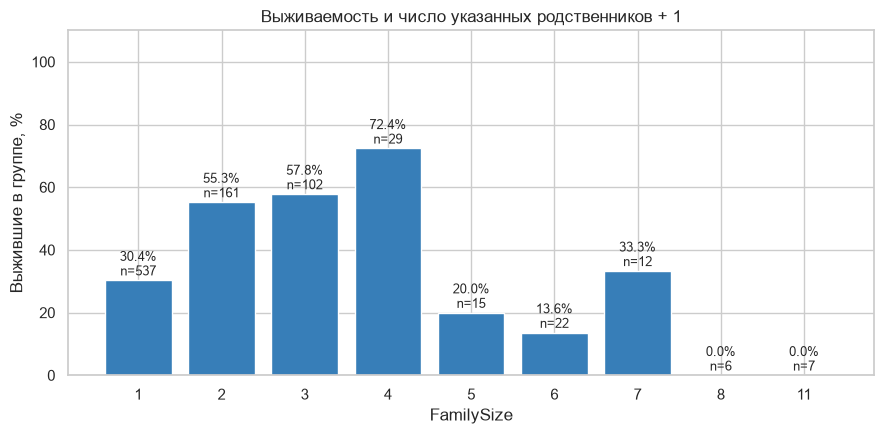

In [27]:
eda_train["FamilySize"] = eda_train["SibSp"] + eda_train["Parch"] + 1
eda_train["IsAlone"] = (eda_train["FamilySize"] == 1).astype(int)
family_summary = eda_train.groupby("FamilySize")["Survived"].agg(
    count="count", survived="sum", survival_percent="mean",
)
family_summary["survival_percent"] *= 100
display(family_summary.round(2))
print("Без указанных родственников:", eda_train["IsAlone"].sum(), "из", len(eda_train))
plot_survival(family_summary, "Выживаемость и число указанных родственников + 1", "FamilySize")

В train 537 из 891 записей имеют SibSp=Parch=0.
Для размеров 2–4 доля выживших выше, чем для размера 1, а некоторые большие группы малы
и имеют низкую наблюдаемую долю выживания. Это нелинейная связь, которую Pearson может описывать плохо.
Нулевую выживаемость в маленькой группе нельзя переносить на всех будущих пассажиров.

### 9.1. Сам факт отсутствия данных

In [28]:
missingness_tables = []
for column in ["Age", "Cabin"]:
    status = train[column].isna().map({False: "Known", True: "Missing"})
    summary = train.groupby(status)["Survived"].agg(
        count="count", survived="sum", survival_percent="mean",
    )
    summary["survival_percent"] *= 100
    summary.index.name = "status"
    summary["feature"] = column
    missingness_tables.append(summary.reset_index())
missingness_summary = pd.concat(missingness_tables, ignore_index=True)
display(missingness_summary[["feature", "status", "count", "survived", "survival_percent"]].round(2))

,feature,status,count,survived,survival_percent
0,Age,Known,714,290,40.62
1,Age,Missing,177,52,29.38
2,Cabin,Known,204,136,66.67
3,Cabin,Missing,687,206,29.99


При известном Cabin доля выживших выше, чем при пропущенном.

## 10. Корреляции числовых полей

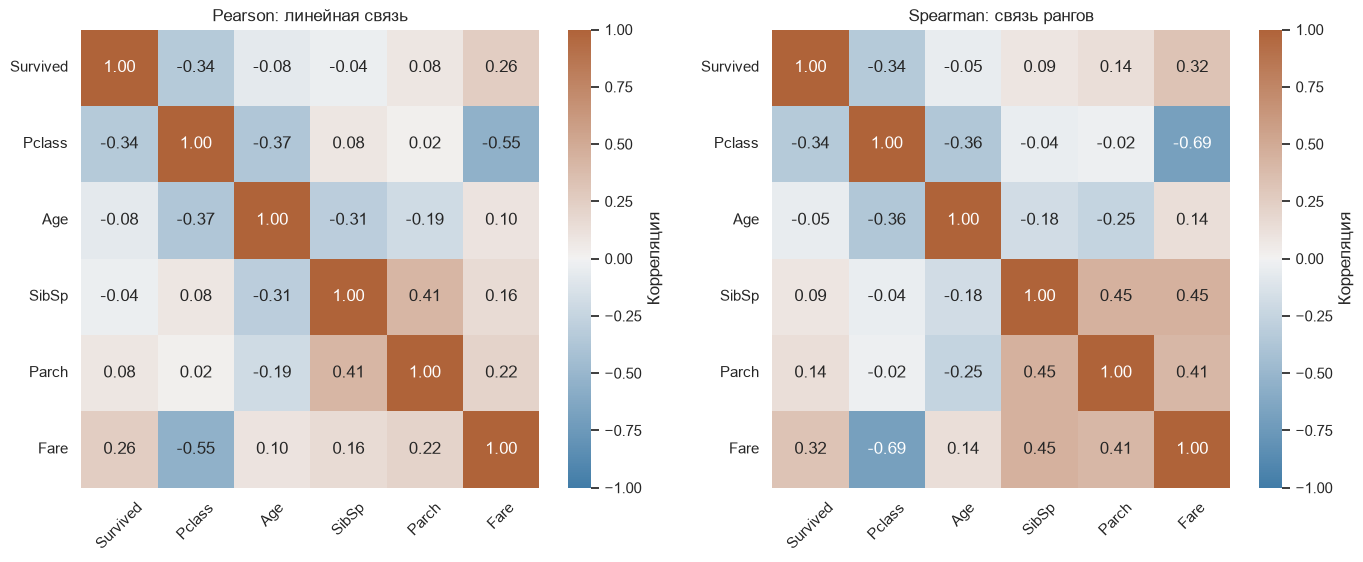

Корреляции с таргетом:


,Pearson,Spearman
Pclass,-0.338,-0.340
Age,-0.077,-0.053
SibSp,-0.035,0.089
Parch,0.082,0.138
Fare,0.257,0.324


Пары признаков с |Pearson| >= 0.8:


,,correlation


In [29]:
numeric_columns = train.select_dtypes(include="number").columns.drop("PassengerId")
numeric_train = train[numeric_columns]
pearson = numeric_train.corr(method="pearson")
spearman = numeric_train.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
correlation_palette = sns.diverging_palette(240, 30, as_cmap=True)
for ax, matrix, title in zip(axes, [pearson, spearman], ["Pearson: линейная связь", "Spearman: связь рангов"]):
    sns.heatmap(matrix, vmin=-1, vmax=1, center=0, cmap=correlation_palette,
                annot=True, fmt=".2f", square=True, ax=ax,
                cbar_kws={"label": "Корреляция"})
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=45)
    ax.tick_params(axis="y", labelrotation=0)
fig.tight_layout()
plt.show()

print("Корреляции с таргетом:")
display(pd.DataFrame({"Pearson": pearson["Survived"], "Spearman": spearman["Survived"]})
        .drop(index="Survived").round(3))
feature_correlations = pearson.drop(index="Survived", columns="Survived")
upper_mask = np.triu(np.ones(feature_correlations.shape, dtype=bool), k=1)
correlated_pairs = feature_correlations.where(upper_mask).stack()
print("Пары признаков с |Pearson| >= 0.8:")
display(correlated_pairs[correlated_pairs.abs() >= 0.8].rename("correlation").to_frame())

У Pclass отрицательная связь с исходом: больший номер означает более низкий класс.
У Fare связь положительная. Среди исходных числовых признаков без ID нет пар с |Pearson| ≥ 0.8;

## 11. Схема, допустимые значения, константы и ID-like поля

In [39]:
feature_columns = train.columns.drop(["Survived", "PassengerId"])
assert "Survived" not in test.columns, "В test есть таргет"
assert list(train.columns.drop("Survived")) == list(test.columns), "Различается схема train/test"
assert train["Survived"].notna().all() and set(train["Survived"].unique()) == {0, 1}, "Неожиданные значения таргета"
for name, frame in [("train", train), ("test", test)]:
    assert frame["PassengerId"].notna().all() and frame["PassengerId"].is_unique, f"Неверный ID в {name}"
    assert frame["Pclass"].isin([1, 2, 3]).all(), f"Неизвестный Pclass в {name}"
    assert frame["Sex"].isin(["male", "female"]).all(), f"Неизвестный Sex в {name}"
    assert frame["Embarked"].dropna().isin(["S", "C", "Q"]).all(), f"Неизвестный Embarked в {name}"
    for column in ["Age", "Fare", "SibSp", "Parch"]:
        assert frame[column].dropna().ge(0).all(), f"Отрицательные значения {name}.{column}"
    for column in ["SibSp", "Parch"]:
        assert frame[column].dropna().mod(1).eq(0).all(), f"Не целый счётчик {name}.{column}"
assert set(train["PassengerId"]).isdisjoint(test["PassengerId"]), "Пересекаются ID"
print("OK")

constant_columns = [column for column in feature_columns if train[column].nunique(dropna=False) <= 1]
dominant_share = pd.Series({
    column: train[column].value_counts(dropna=False, normalize=True).iloc[0]
    for column in feature_columns
})
print("Константные признаки:", constant_columns)
print("Почти константные (самое частое значение >=95%):")
display(dominant_share[dominant_share >= 0.95].mul(100).rename("dominant_percent").to_frame())
uniqueness_summary = pd.DataFrame({
    "non_missing": train.notna().sum(), "n_unique": train.nunique(),
})
uniqueness_summary["unique_percent_of_non_missing"] = (
    uniqueness_summary["n_unique"] / uniqueness_summary["non_missing"] * 100
)
display(uniqueness_summary.sort_values("unique_percent_of_non_missing", ascending=False).round(2))

OK
Константные признаки: []
Почти константные (самое частое значение >=95%):


,dominant_percent


,non_missing,n_unique,unique_percent_of_non_missing
PassengerId,891,891,100.00
Name,891,891,100.00
Ticket,891,681,76.43
Cabin,204,147,72.06
Fare,891,248,27.83
Age,714,88,12.32
SibSp,891,7,0.79
Parch,891,7,0.79
Embarked,889,3,0.34
Pclass,891,3,0.34


Константных и почти константных
признаков при пороге 95% нет. PassengerId и Name уникальны внутри train.
ID исключим из первого baseline.

### 11.1. Повторы без ID и пересечения между наборами

In [31]:
for name, frame in [("train", train), ("test", test)]:
    print(f"{name}: повторы всех признаков без ID/таргета =",
          frame.duplicated(subset=list(feature_columns)).sum())
train_rows = train[feature_columns].drop_duplicates()
test_rows = test[feature_columns].drop_duplicates()
exact_overlap = train_rows.merge(test_rows, on=list(feature_columns), how="inner")
print("Совпадающие разные записи train/test по всем признакам без ID:", len(exact_overlap))
print("Повторяющихся имён в test:", test["Name"].duplicated().sum())

train: повторы всех признаков без ID/таргета = 0
test: повторы всех признаков без ID/таргета = 0
Совпадающие разные записи train/test по всем признакам без ID: 0
Повторяющихся имён в test: 0


## 12. Общие билеты и риск зависимости между фолдами

In [32]:
train_ticket_counts = train["Ticket"].dropna().value_counts()
repeated_tickets = train_ticket_counts[train_ticket_counts > 1]
shared_tickets = set(train["Ticket"].dropna()) & set(test["Ticket"].dropna())
ticket_group_checks = pd.Series({
    "Повторяющиеся билеты в train": len(repeated_tickets),
    "Строки train с повторяющимися билетами": train["Ticket"].isin(repeated_tickets.index).sum(),
    "Разных билетов, общих для train/test": len(shared_tickets),
    "Строки train с общими билетами": train["Ticket"].isin(shared_tickets).sum(),
    "Строки test с общими билетами": test["Ticket"].isin(shared_tickets).sum(),
})
display(ticket_group_checks.to_frame("count"))
display(repeated_tickets.head(10).rename("train_group_size").to_frame())

,count
Повторяющиеся билеты в train,134
Строки train с повторяющимися билетами,344
"Разных билетов, общих для train/test",115
Строки train с общими билетами,207
Строки test с общими билетами,152


,train_group_size
Ticket,
347082,7
1601,7
CA. 2343,7
3101295,6
CA 2144,6
347088,6
382652,5
S.O.C. 14879,5
349909,4


Билеты повторяются внутри train и встречаются в обоих наборах.
Случайный стратифицированный split может разделить связанных пассажиров между train/validation.

## 13. Сопоставимость train/test

count   mean    std   min    25%    50%   75%     max
dataset feature                                                       
train   Age      714.0  29.70  14.53  0.42  20.12  28.00  38.0   80.00
        Fare     891.0  32.20  49.69  0.00   7.91  14.45  31.0  512.33
test    Age      332.0  30.27  14.18  0.17  21.00  27.00  39.0   76.00
        Fare     417.0  35.63  55.91  0.00   7.90  14.45  31.5  512.33

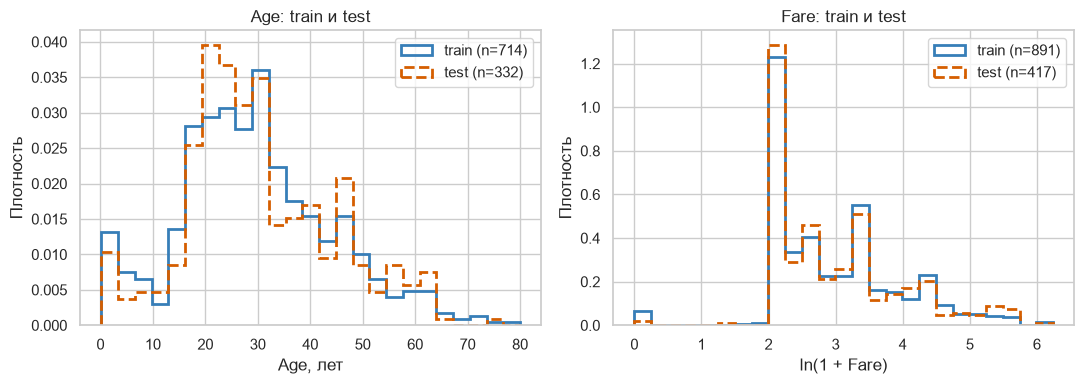

Доли категорий Sex, % (пропуск = Unknown):


,train,test
Sex,,
male,64.76,63.64
female,35.24,36.36


Доли категорий Pclass, % (пропуск = Unknown):


,train,test
Pclass,,
3,55.11,52.15
1,24.24,25.60
2,20.65,22.25


Доли категорий Embarked, % (пропуск = Unknown):


,train,test
Embarked,,
S,72.28,64.59
C,18.86,24.40
Q,8.64,11.00
Unknown,0.22,0.00


In [33]:
distribution_summary = pd.concat({
    "train": train[["Age", "Fare"]].describe().T,
    "test": test[["Age", "Fare"]].describe().T,
}, names=["dataset", "feature"])
display(distribution_summary[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column, transform, label in [
    (axes[0], "Age", lambda values: values, "Age, лет"),
    (axes[1], "Fare", np.log1p, "ln(1 + Fare)"),
]:
    train_values = transform(train[column].dropna())
    test_values = transform(test[column].dropna())
    common_bins = np.histogram_bin_edges(pd.concat([train_values, test_values]), bins=25)
    ax.hist(train_values, bins=common_bins, density=True, histtype="step", linewidth=2,
            color="#377eb8", label=f"train (n={len(train_values)})")
    ax.hist(test_values, bins=common_bins, density=True, histtype="step", linewidth=2,
            linestyle="--", color="#d55e00", label=f"test (n={len(test_values)})")
    ax.set(title=f"{column}: train и test", xlabel=label, ylabel="Плотность")
    ax.legend()
fig.tight_layout()
plt.show()

for column in ["Sex", "Pclass", "Embarked"]:
    print(f"Доли категорий {column}, % (пропуск = Unknown):")
    category_shares = pd.concat({
        "train": train[column].fillna("Unknown").value_counts(normalize=True),
        "test": test[column].fillna("Unknown").value_counts(normalize=True),
    }, axis=1).fillna(0).mul(100)
    display(category_shares.round(2))

Диапазоны и основные области распределений похожи

## 14. Итог
Наиболее выраженные различия обнаружены по полу и классу билета. Также выявлены пропуски, асимметричное распределение стоимости билетов и возможная зависимость записей по общим билетам. Эти наблюдения позволяют сформулировать гипотезы для моделирования.

## Структура и качество данных

Обучающая выборка содержит 891 запись и 12 столбцов, тестовая — 418 записей и 11 столбцов. Целевая переменная Survived присутствует только в train: 0 обозначает гибель пассажира, 1 выживание. PassengerId является идентификатором.

Полных дубликатов, а также точных повторов набора признаков без идентификатора и таргета не обнаружено. Базовые проверки схемы и допустимых значений пройдены. Константных признаков и почти константных полей, в которых одно значение занимает не менее 95% записей, нет.

## Распределение таргета

В train погибли 549 пассажиров — 61.62%, выжили 342 — 38.38%. Наблюдается умеренный дисбаланс классов. Постоянное предсказание смерти даёт accuracy 61.62% на этой выборке - ориентир для бейслайна.

При разбиении данных будем сохранять доли классов с помощью стратификации.

## Пропуски

Основные пропуски находятся в Age и Cabin. Возраст неизвестен у 19.87% записей train и 20.57% test; каюта — у 77.10% и 78.23% соответственно. Дополнительно отсутствуют два значения Embarked в train и одно значение Fare в test.

Обработку необходимо предусмотреть для всех четырёх полей. Кандидатами являются заполнение числовых пропусков медианой, обработка неизвестных категорий и добавление индикаторов пропусков.

Среди записей с известной каютой выживаемость составляет 66.67%, с неизвестной — 29.99%.

## Связь признаков с выживаемостью

Среди 314 женщин выжили 74.20%, среди 577 мужчин — 18.89%. Различие сохраняется внутри каждого класса билета.

Выживаемость также различается по классу: 62.96% в первом классе, 47.28% во втором и 24.24% в третьем. Совместный анализ пола и класса показывает дополнительную структуру: среди женщин первого и второго классов выживаемость превышает 90%, среди женщин третьего класса составляет 50%.

Доли выживших различаются и между портами посадки. Однако состав классов билета в этих группах неодинаков, поэтому нельзя приписывать различия исключительно порту.

## Числовые признаки и родственники

Медиана известного возраста составляет 28 лет. Среди детей младше 12 лет выжили 39 из 68 пассажиров — 57.35%. При этом линейная корреляция возраста с исходом слабая. Следовательно, слабая корреляция не означает бесполезность возраста: связь может быть нелинейной.

Распределение Fare имеет длинный правый хвост: среднее составляет около 32.20, медиана — 14.45, максимум — 512.33. Высокие значения нельзя автоматически считать ошибками. Логарифмическое преобразование является кандидатом для эксперимента.

У 537 пассажиров оба счётчика родственников равны нулю. Для FamilySize от 2 до 4 наблюдается более высокая выживаемость, чем для значения 1. Оценки больших групп менее устойчивы из-за небольшого числа записей. FamilySize и IsAlone следует проверить как дополнительные признаки.

## Категории, корреляции и валидация

Name, Ticket и Cabin содержат много уникальных или редких значений; в test встречаются новые строки.

Среди исходных числовых признаков без ID не обнаружено пар с абсолютной корреляцией Pearson не менее 0.8

Билеты повторяются внутри train; 115 разных билетов встречаются одновременно в train и test. Поэтому случайное разбиение может распределить связанных пассажиров между обучением и валидацией. 

## Общий вывод

EDA сформировал гипотезы: обработка пропусков и их индикаторов, преобразование Fare, взаимодействие пола и класса, признаки родственников.

### 14.1. Финальная проверка воспроизводимости

In [40]:
pd.testing.assert_frame_equal(train, raw_train)
pd.testing.assert_frame_equal(test, raw_test)
for summary in [target_summary, sex_summary, pclass_summary, sex_pclass_summary,
                embarked_summary, age_summary, family_summary]:
    assert int(summary["count"].sum()) == len(train), "Группы потеряли записи"
for summary in [sex_summary, pclass_summary, sex_pclass_summary,
                embarked_summary, age_summary, family_summary]:
    assert int(summary["survived"].sum()) == int(train["Survived"].sum()), "Не сходится число выживших"
print("EDA выполнен: группы сходятся, исходные train/test не поменялись -> ничего не сломали")

EDA выполнен: группы сходятся, исходные train/test не поменялись -> ничего не сломали
